# Lab 4: Regression Analysis with Regularization Techniques
**Name:** Sowmya Cheruku  
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**University:** University of the Cumberlands  
**Instructor:** Satish Penmatsa  
**Lab:** Lab 4 – Regression Analysis with Regularization Techniques

## Introduction
In this lab I use the Diabetes dataset from scikit-learn to predict disease progression one year after baseline. I start with simple linear regression, move to multiple and polynomial regression, and then try Ridge and Lasso to see if regularization helps with overfitting. Every model is scored with MAE, MSE, RMSE and R².

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
np.random.seed(42)

## Step 1: Data Preparation

In [2]:
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = pd.Series(diabetes.target, name="progression")

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
X.head()

Shape of X: (442, 10)
Shape of y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


The dataset has 442 patients and 10 features (age, sex, bmi, bp, and six blood serum measurements s1–s6). The target is a number that measures how much the disease progressed. Sklearn already mean-centered and scaled the features, which is why the values look small.

In [3]:
print(X.describe().round(3))
print("\nTarget summary:")
print(y.describe().round(2))

           age      sex      bmi       bp       s1       s2       s3       s4  \
count  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000   
mean    -0.000    0.000   -0.000   -0.000   -0.000    0.000   -0.000   -0.000   
std      0.048    0.048    0.048    0.048    0.048    0.048    0.048    0.048   
min     -0.107   -0.045   -0.090   -0.112   -0.127   -0.116   -0.102   -0.076   
25%     -0.037   -0.045   -0.034   -0.037   -0.034   -0.030   -0.035   -0.039   
50%      0.005   -0.045   -0.007   -0.006   -0.004   -0.004   -0.007   -0.003   
75%      0.038    0.051    0.031    0.036    0.028    0.030    0.029    0.034   
max      0.111    0.051    0.171    0.132    0.154    0.199    0.181    0.185   

            s5       s6  
count  442.000  442.000  
mean     0.000    0.000  
std      0.048    0.048  
min     -0.126   -0.138  
25%     -0.033   -0.033  
50%     -0.002   -0.001  
75%      0.032    0.028  
max      0.134    0.136  

Target summary:
count    442.00
mea

In [4]:
# Check for missing values and duplicates
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())
print("Duplicate rows:", X.duplicated().sum())

Missing values in X: 0
Missing values in y: 0
Duplicate rows: 0


There are no missing values or duplicates, so no cleaning was needed.

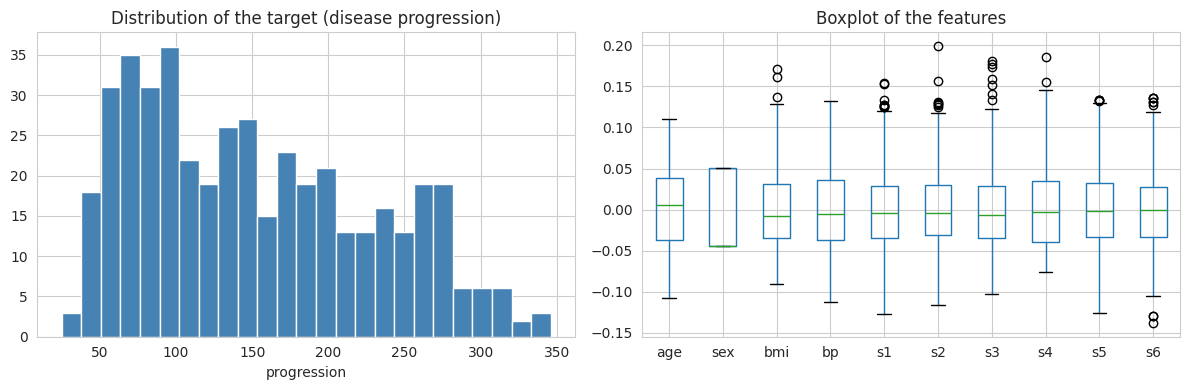

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=25, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of the target (disease progression)")
axes[0].set_xlabel("progression")
X.boxplot(ax=axes[1])
axes[1].set_title("Boxplot of the features")
plt.tight_layout()
plt.show()

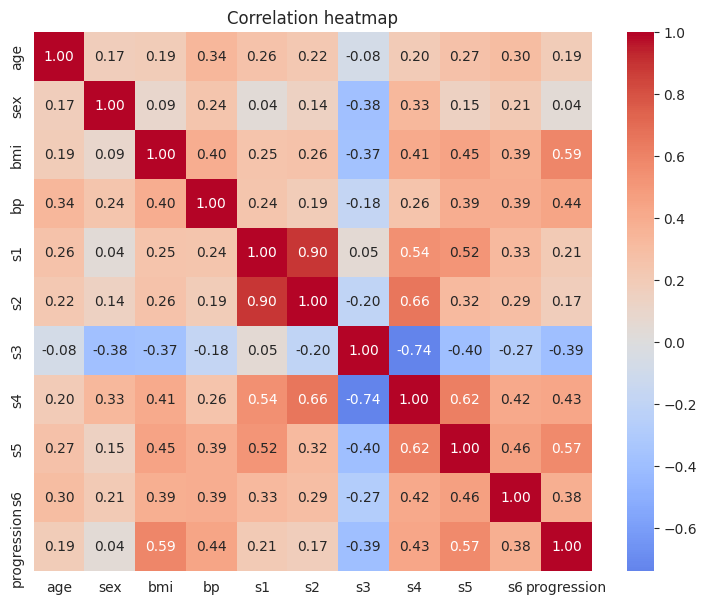

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: progression, dtype: float64


In [6]:
corr = pd.concat([X, y], axis=1).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

print(corr["progression"].drop("progression").sort_values(ascending=False).round(3))

**What I noticed:** The target is a bit right-skewed. `bmi` and `s5` have the strongest correlation with progression, and `bp` is next. Some of the serum features (`s1` and `s2`, also `s3` and `s4`) are highly correlated with each other. That is multicollinearity, and it should matter later when I use Ridge and Lasso.

### Train/test split and helper function
I use one 80/20 split for every model so the comparison is fair. I also made a small function that computes all four metrics so I don't repeat code.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

results = []   # I will store every model's scores here for the final comparison

def evaluate(name, y_true, y_pred, store=True):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    if store:
        results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})
    return mae, mse, rmse, r2

def show(name, metrics):
    print(f"{name}\n  MAE  = {metrics[0]:.2f}\n  MSE  = {metrics[1]:.2f}\n  RMSE = {metrics[2]:.2f}\n  R2   = {metrics[3]:.4f}")

Train size: 353 | Test size: 89


## Step 2: Simple Linear Regression

I picked `bmi` as the single feature because it had the highest correlation with the target.

In [8]:
Xtr_bmi = X_train[["bmi"]]
Xte_bmi = X_test[["bmi"]]

slr = LinearRegression()
slr.fit(Xtr_bmi, y_train)
pred_slr = slr.predict(Xte_bmi)

print("Intercept:", round(slr.intercept_, 2), "| Slope:", round(slr.coef_[0], 2))
show("Simple Linear Regression (bmi)", evaluate("Simple Linear (bmi)", y_test, pred_slr))

Intercept: 152.0 | Slope: 998.58
Simple Linear Regression (bmi)
  MAE  = 52.26
  MSE  = 4061.83
  RMSE = 63.73
  R2   = 0.2334


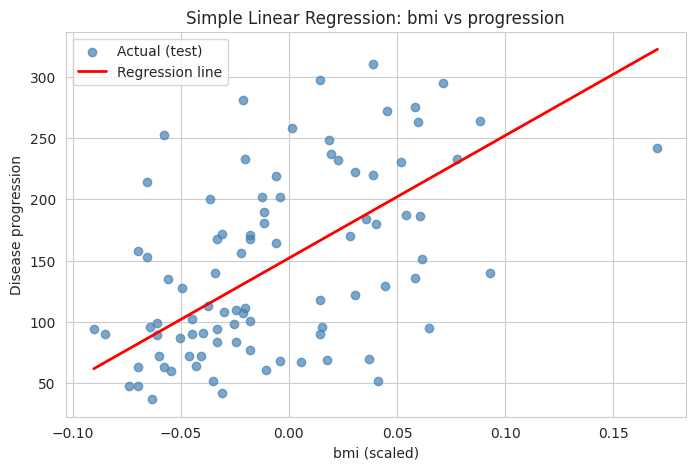

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(Xte_bmi, y_test, color="steelblue", alpha=0.7, label="Actual (test)")
order = np.argsort(Xte_bmi.values.ravel())
plt.plot(Xte_bmi.values.ravel()[order], pred_slr[order], color="red", linewidth=2, label="Regression line")
plt.xlabel("bmi (scaled)")
plt.ylabel("Disease progression")
plt.title("Simple Linear Regression: bmi vs progression")
plt.legend()
plt.show()

**Interpretation:** BMI by itself explains only a modest part of the variation (see R² above). The points are very spread out around the line, so one feature is not enough to predict progression well.

## Step 3: Multiple Regression

In [10]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
pred_mlr = mlr.predict(X_test)

show("Multiple Regression (all 10 features) - TEST", evaluate("Multiple Linear", y_test, pred_mlr))
print()
show("Multiple Regression - TRAIN (just for comparison)", evaluate("", y_train, mlr.predict(X_train), store=False))

coef_df = pd.DataFrame({"feature": X.columns, "coefficient": mlr.coef_}).sort_values("coefficient")
print()
print(coef_df.round(2).to_string(index=False))

Multiple Regression (all 10 features) - TEST
  MAE  = 42.79
  MSE  = 2900.19
  RMSE = 53.85
  R2   = 0.4526

Multiple Regression - TRAIN (just for comparison)
  MAE  = 43.48
  MSE  = 2868.55
  RMSE = 53.56
  R2   = 0.5279

feature  coefficient
     s1      -931.49
    sex      -241.96
    age        37.90
     s6        48.67
     s3       163.42
     s4       275.32
     bp       347.70
     s2       518.06
    bmi       542.43
     s5       736.20


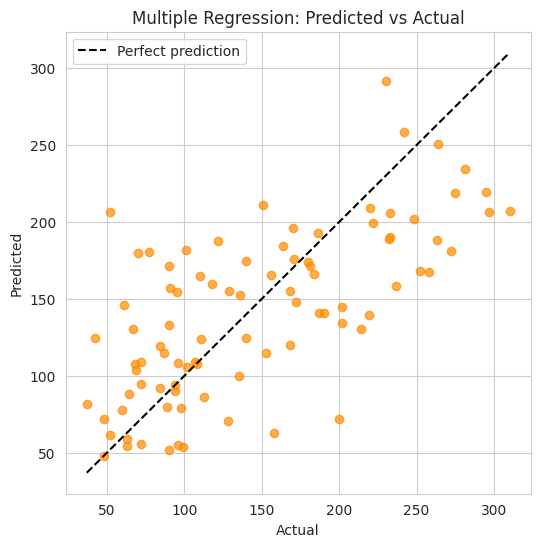

In [11]:
def pred_vs_actual(y_true, y_pred, title):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.7, color="darkorange")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    plt.plot(lims, lims, "k--", label="Perfect prediction")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(title)
    plt.legend()
    plt.show()

pred_vs_actual(y_test, pred_mlr, "Multiple Regression: Predicted vs Actual")

**Interpretation:** Using all features gives a clear improvement over the BMI-only model. The points sit closer to the dashed line, but there is still a lot of scatter, so a linear model on this data has a limit. Some coefficients are large and have opposite signs (for example `s1`, `s2`), which is a sign of the multicollinearity I saw in the heatmap.

## Step 4: Polynomial Regression

To show over/underfitting clearly, I first use only `bmi` and try different polynomial degrees. This way I can plot the curves.

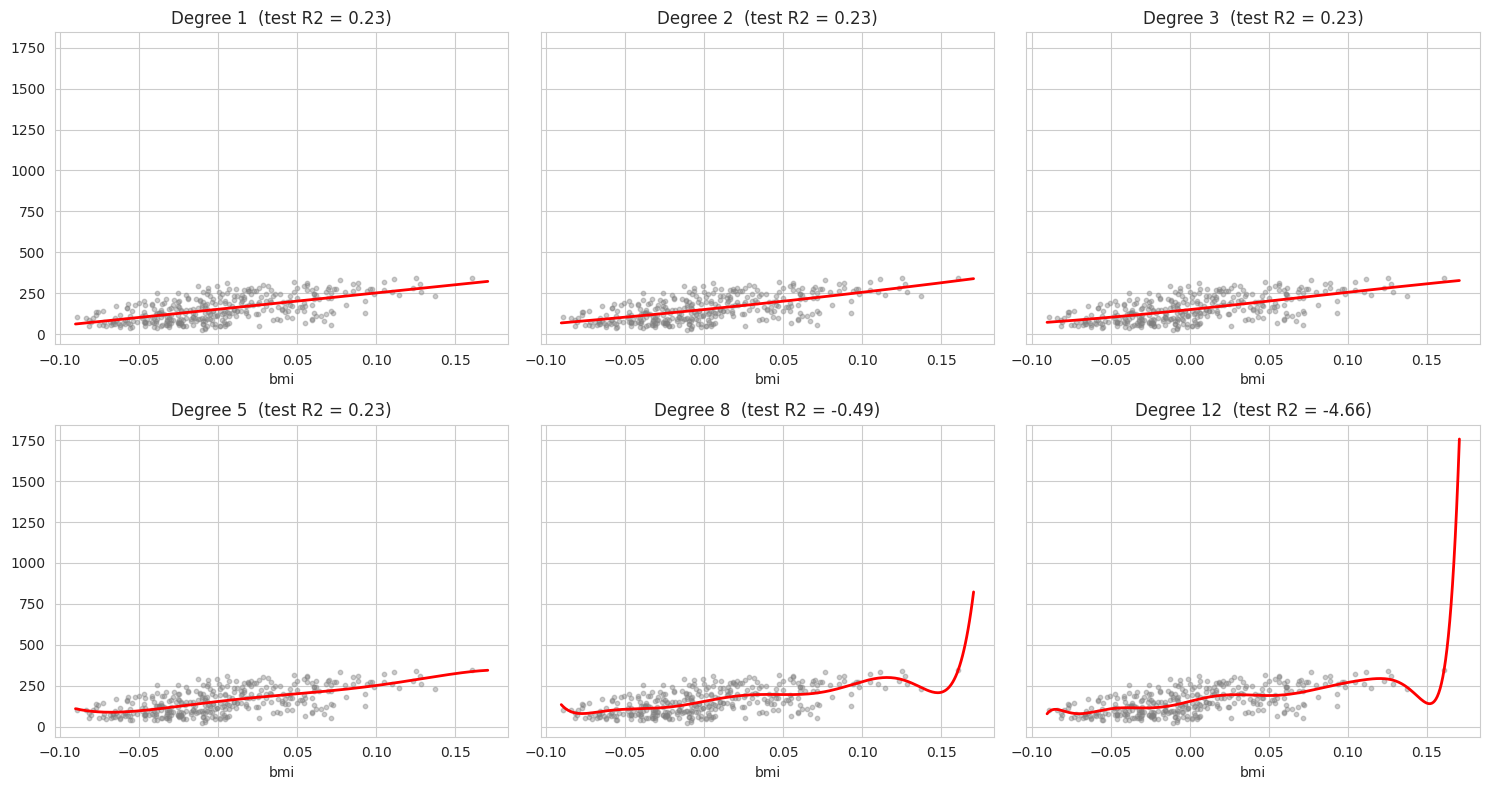

,degree,Train RMSE,Test RMSE,Train R2,Test R2
0,1,62.082,63.732,0.366,0.233
1,2,62.043,63.914,0.367,0.229
2,3,62.036,63.753,0.367,0.233
3,5,61.837,63.921,0.371,0.229
4,8,61.116,88.743,0.385,-0.486
5,12,60.895,173.171,0.390,-4.660


In [12]:
degrees = [1, 2, 3, 5, 8, 12]
rows = []
xs = np.linspace(X["bmi"].min(), X["bmi"].max(), 300).reshape(-1, 1)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, d in zip(axes.ravel(), degrees):
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(Xtr_bmi, y_train)
    tr = evaluate("", y_train, model.predict(Xtr_bmi), store=False)
    te = evaluate("", y_test, model.predict(Xte_bmi), store=False)
    rows.append({"degree": d, "Train RMSE": tr[2], "Test RMSE": te[2], "Train R2": tr[3], "Test R2": te[3]})
    ax.scatter(Xtr_bmi, y_train, s=10, alpha=0.4, color="gray")
    ax.plot(xs, model.predict(xs), color="red", linewidth=2)
    ax.set_title(f"Degree {d}  (test R2 = {te[3]:.2f})")
    ax.set_xlabel("bmi")
plt.tight_layout()
plt.show()

poly_table = pd.DataFrame(rows).round(3)
poly_table

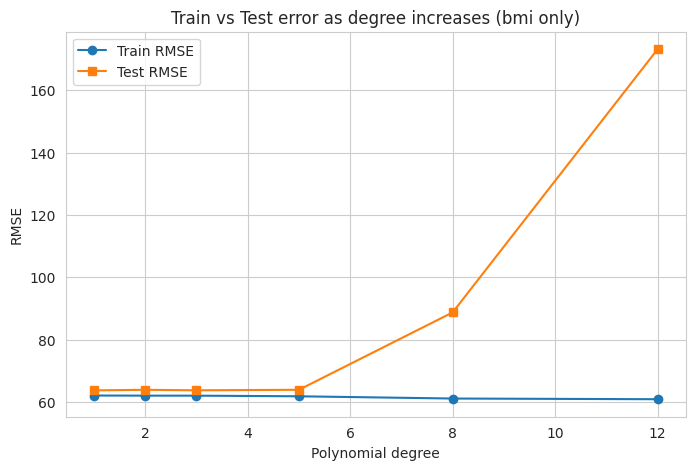

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(poly_table["degree"], poly_table["Train RMSE"], "o-", label="Train RMSE")
plt.plot(poly_table["degree"], poly_table["Test RMSE"], "s-", label="Test RMSE")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE")
plt.title("Train vs Test error as degree increases (bmi only)")
plt.legend()
plt.show()

**Under/overfitting:** With `bmi` only, degrees 1 to 5 all give almost the same test error (RMSE about 64) and a low train R² (about 0.37). That means these models are **underfitting**: one feature just doesn't contain enough information, and making the curve more flexible doesn't fix that. Once the degree gets large (8 and 12), the training error goes down slightly but the test error blows up (test R² goes negative). The curve starts wiggling to follow noise in the training points, which is **overfitting**.

Next I apply polynomial features to **all** 10 features so I can compare with the multiple regression model.

In [14]:
# degree 2 on all features -> 65 features
poly2 = make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression())
poly2.fit(X_train, y_train)
pred_poly2 = poly2.predict(X_test)
print("Number of features after degree 2:", poly2.named_steps["polynomialfeatures"].n_output_features_)
show("Polynomial (degree 2, all features) - TEST", evaluate("Polynomial deg 2 (all)", y_test, pred_poly2))
print()
show("Polynomial (degree 2, all features) - TRAIN", evaluate("", y_train, poly2.predict(X_train), store=False))

# degree 3 on all features -> 285 features, much more than needed for 353 training rows
poly3 = make_pipeline(PolynomialFeatures(3, include_bias=False), LinearRegression())
poly3.fit(X_train, y_train)
pred_poly3 = poly3.predict(X_test)
print("\nNumber of features after degree 3:", poly3.named_steps["polynomialfeatures"].n_output_features_)
show("Polynomial (degree 3, all features) - TEST", evaluate("Polynomial deg 3 (all)", y_test, pred_poly3))
print()
show("Polynomial (degree 3, all features) - TRAIN", evaluate("", y_train, poly3.predict(X_train), store=False))

Number of features after degree 2: 65
Polynomial (degree 2, all features) - TEST
  MAE  = 43.58
  MSE  = 3096.03
  RMSE = 55.64
  R2   = 0.4156

Polynomial (degree 2, all features) - TRAIN
  MAE  = 39.14
  MSE  = 2393.14
  RMSE = 48.92
  R2   = 0.6062

Number of features after degree 3: 285
Polynomial (degree 3, all features) - TEST
  MAE  = 164.85
  MSE  = 82446.05
  RMSE = 287.13
  R2   = -14.5613

Polynomial (degree 3, all features) - TRAIN
  MAE  = 18.69
  MSE  = 745.62
  RMSE = 27.31
  R2   = 0.8773


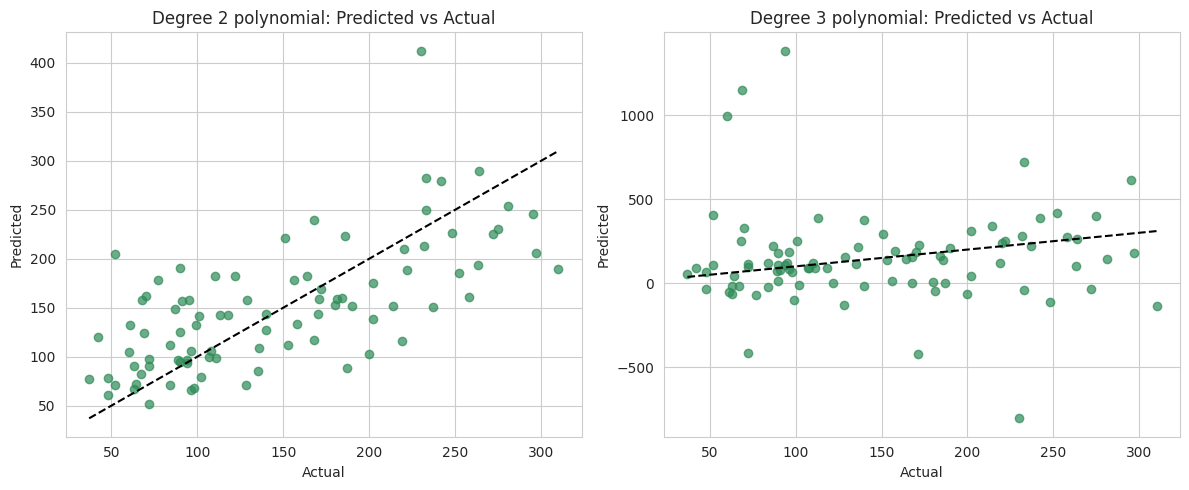

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, t in zip(axes, [pred_poly2, pred_poly3], ["Degree 2", "Degree 3"]):
    ax.scatter(y_test, pred, alpha=0.7, color="seagreen")
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")
    ax.set_title(f"{t} polynomial: Predicted vs Actual")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
plt.tight_layout()
plt.show()

**Comparison:** Degree 2 on all features gets a lower training error than multiple regression (RMSE about 49 vs 54), but its test error is a bit worse (about 55.6 vs 53.9), so it is already starting to overfit. Degree 3 has 285 features for only 353 training rows, and it fits the training data very well (train R² about 0.88) but the test R² is hugely negative. This is the problem regularization is supposed to fix.

## Step 5: Regularization with Ridge and Lasso

Ridge adds an L2 penalty (alpha × sum of squared coefficients) and shrinks coefficients toward zero. Lasso adds an L1 penalty (alpha × sum of absolute coefficients) and can push some coefficients to exactly zero, so it also does feature selection. Because the penalty depends on the size of the coefficients, I scale the features first (they are almost scaled already, but it is good practice).

In [16]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
rows = []
for a in alphas:
    r = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    l = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50000)).fit(X_train, y_train)
    rr = evaluate("", y_test, r.predict(X_test), store=False)
    lr_ = evaluate("", y_test, l.predict(X_test), store=False)
    rows.append({"alpha": a,
                 "Ridge RMSE": rr[2], "Ridge R2": rr[3],
                 "Lasso RMSE": lr_[2], "Lasso R2": lr_[3],
                 "Lasso zero coefs": int(np.sum(l.named_steps["lasso"].coef_ == 0))})
alpha_table = pd.DataFrame(rows).round(3)
alpha_table

,alpha,Ridge RMSE,Ridge R2,Lasso RMSE,Lasso R2,Lasso zero coefs
0,0.001,53.853,0.453,53.852,0.453,0
1,0.010,53.852,0.453,53.836,0.453,0
2,0.100,53.843,0.453,53.709,0.456,0
3,1.000,53.777,0.454,53.147,0.467,1
4,10.000,53.626,0.457,54.165,0.446,6
5,100.000,53.462,0.461,73.222,-0.012,10


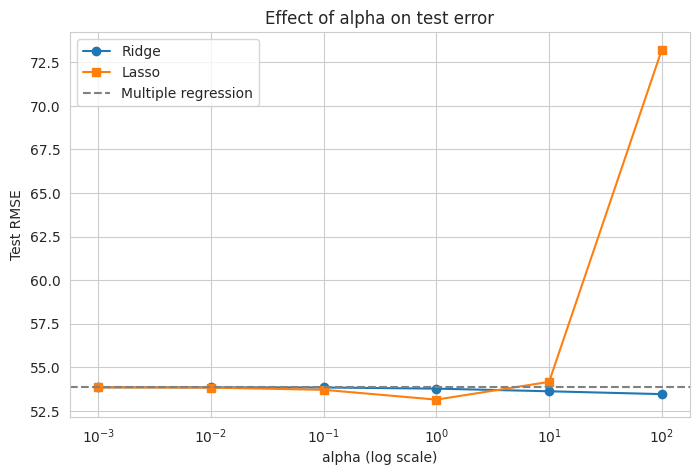

In [17]:
plt.figure(figsize=(8, 5))
plt.semilogx(alpha_table["alpha"], alpha_table["Ridge RMSE"], "o-", label="Ridge")
plt.semilogx(alpha_table["alpha"], alpha_table["Lasso RMSE"], "s-", label="Lasso")
plt.axhline(np.sqrt(mean_squared_error(y_test, pred_mlr)), color="gray", linestyle="--", label="Multiple regression")
plt.xlabel("alpha (log scale)")
plt.ylabel("Test RMSE")
plt.title("Effect of alpha on test error")
plt.legend()
plt.show()

### Picking the best alpha with cross-validation
Instead of guessing, I use `RidgeCV` and `LassoCV`, which choose alpha using 5-fold cross-validation on the training data only.

In [18]:
ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5)).fit(X_train, y_train)
lasso_cv = make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-3, 1, 50), cv=5, max_iter=50000)).fit(X_train, y_train)

print("Best Ridge alpha:", round(ridge_cv.named_steps["ridgecv"].alpha_, 3))
print("Best Lasso alpha:", round(lasso_cv.named_steps["lassocv"].alpha_, 3))
print()
pred_ridge = ridge_cv.predict(X_test)
pred_lasso = lasso_cv.predict(X_test)
show("Ridge (best alpha)", evaluate("Ridge (CV alpha)", y_test, pred_ridge))
print()
show("Lasso (best alpha)", evaluate("Lasso (CV alpha)", y_test, pred_lasso))

Best Ridge alpha: 44.984
Best Lasso alpha: 1.526

Ridge (best alpha)
  MAE  = 43.01
  MSE  = 2856.84
  RMSE = 53.45
  R2   = 0.4608

Lasso (best alpha)
  MAE  = 42.78
  MSE  = 2801.69
  RMSE = 52.93
  R2   = 0.4712


In [19]:
# Regularization on the overfitting polynomial model (degree 3) to see if it helps
for name, reg in [("Ridge", Ridge(alpha=100)), ("Lasso", Lasso(alpha=1, max_iter=100000))]:
    m = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), reg).fit(X_train, y_train)
    p = m.predict(X_test)
    print(f"{name} + degree 3 polynomial")
    show("", evaluate(f"{name} + Poly deg 3", y_test, p))
    print()

Ridge + degree 3 polynomial

  MAE  = 45.77
  MSE  = 3089.72
  RMSE = 55.59
  R2   = 0.4168

Lasso + degree 3 polynomial

  MAE  = 43.23
  MSE  = 2757.19
  RMSE = 52.51
  R2   = 0.4796



### Coefficients and predictions

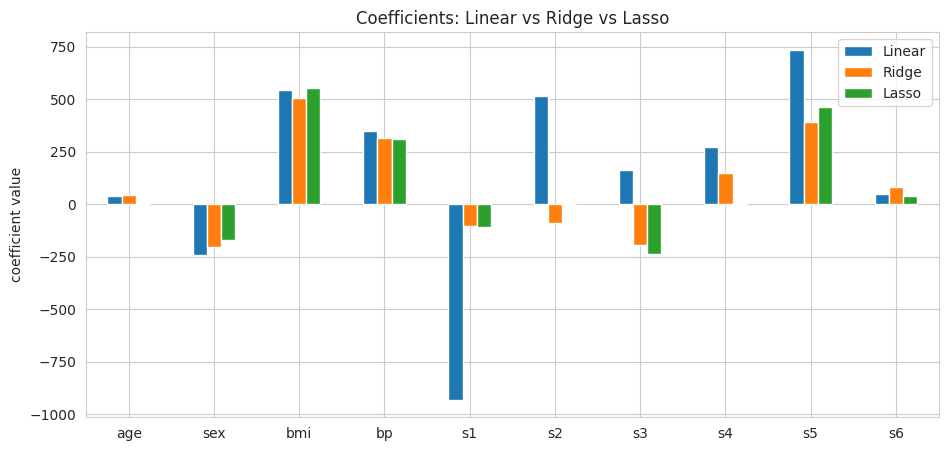

Features Lasso set to zero: ['s2', 's4']


In [20]:
coefs = pd.DataFrame({
    "Linear": mlr.coef_,
    "Ridge": ridge_cv.named_steps["ridgecv"].coef_ / ridge_cv.named_steps["standardscaler"].scale_,
    "Lasso": lasso_cv.named_steps["lassocv"].coef_ / lasso_cv.named_steps["standardscaler"].scale_,
}, index=X.columns)
coefs.round(2).plot(kind="bar", figsize=(11, 5))
plt.title("Coefficients: Linear vs Ridge vs Lasso")
plt.ylabel("coefficient value")
plt.xticks(rotation=0)
plt.show()
print("Features Lasso set to zero:", list(coefs.index[coefs["Lasso"] == 0]))

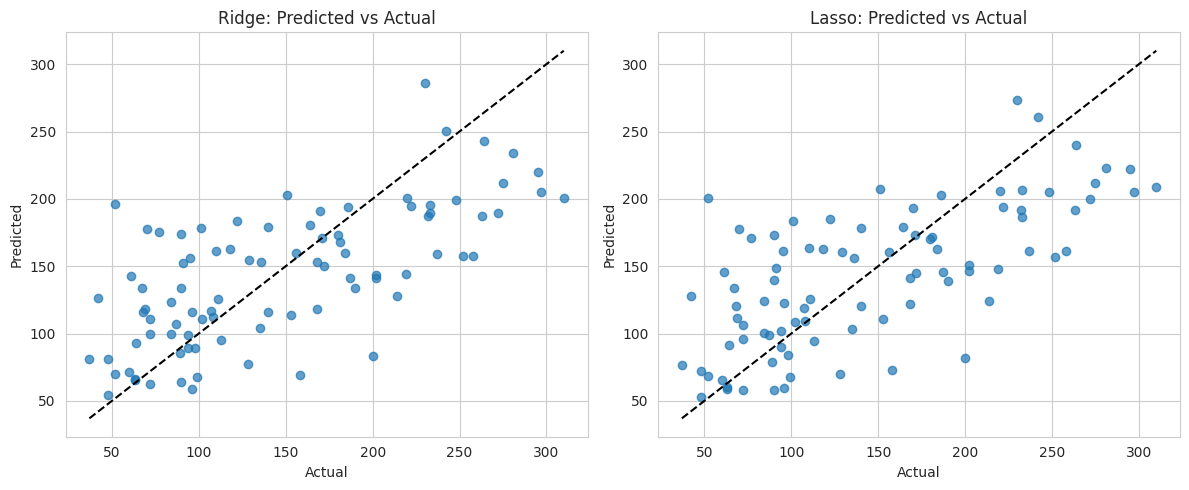

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, t in zip(axes, [pred_ridge, pred_lasso], ["Ridge", "Lasso"]):
    ax.scatter(y_test, pred, alpha=0.7)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "k--")
    ax.set_title(f"{t}: Predicted vs Actual")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
plt.tight_layout()
plt.show()

**How alpha affects the models:** With a tiny alpha, both models behave almost exactly like ordinary linear regression. As alpha increases, the coefficients shrink. Ridge shrinks them smoothly but never to exactly zero. Lasso drops weaker features completely once alpha is large enough. If alpha is too large, the model underfits. For Lasso at alpha = 100 every coefficient is zero, so it just predicts the mean and R² is about 0. Ridge was much more stable across the alpha values I tried, and its best alpha from cross-validation was fairly large (about 45).

## Step 6: Model Comparison and Analysis

In [22]:
comparison = pd.DataFrame(results).set_index("Model").round(3)
comparison.sort_values("RMSE")

,MAE,MSE,RMSE,R2
Model,,,,
Lasso + Poly deg 3,43.232,2757.189,52.509,0.480
Lasso (CV alpha),42.777,2801.688,52.931,0.471
Ridge (CV alpha),43.011,2856.841,53.449,0.461
Multiple Linear,42.794,2900.194,53.853,0.453
Ridge + Poly deg 3,45.767,3089.722,55.585,0.417
Polynomial deg 2 (all),43.582,3096.028,55.642,0.416
Simple Linear (bmi),52.260,4061.826,63.732,0.233
Polynomial deg 3 (all),164.854,82446.048,287.134,-14.561


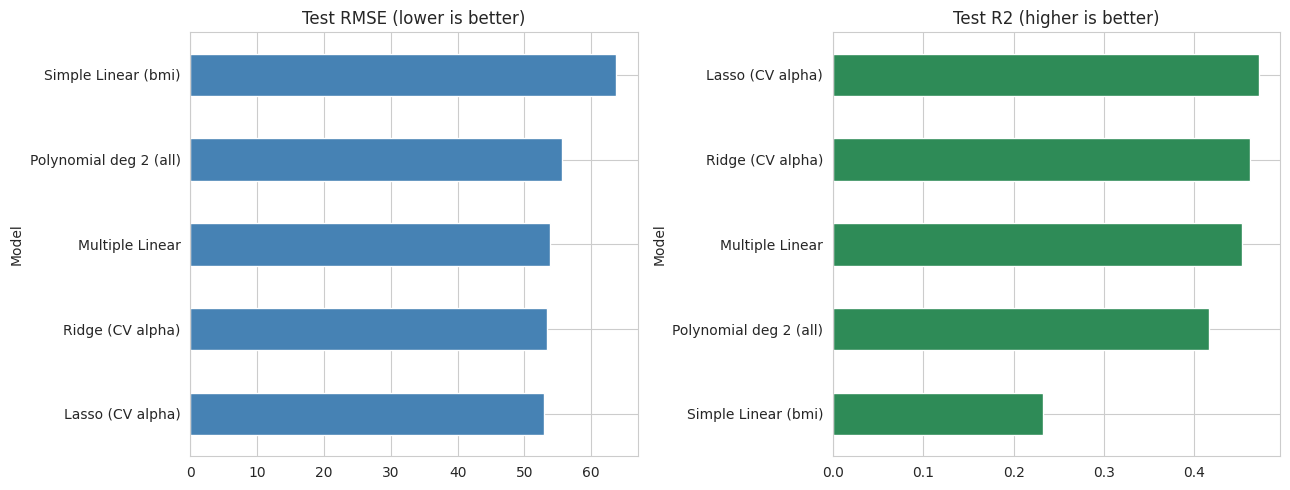

In [23]:
plot_df = comparison.drop(index=[i for i in comparison.index if "deg 3" in i])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_df["RMSE"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Test RMSE (lower is better)")
plot_df["R2"].sort_values().plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_title("Test R2 (higher is better)")
plt.tight_layout()
plt.show()

### Summary of results
| Model | Test RMSE | Test R² |
|---|---|---|
| Simple Linear (bmi) | 63.73 | 0.233 |
| Multiple Linear | 53.85 | 0.453 |
| Polynomial deg 2 (all features) | 55.64 | 0.416 |
| Polynomial deg 3 (all features) | 287.13 | -14.56 |
| Ridge (CV alpha) | 53.45 | 0.461 |
| Lasso (CV alpha) | 52.93 | 0.471 |
| Lasso + Poly deg 3 | 52.51 | 0.480 |

### Key observations
**How well each model did:** The simple BMI model was the weakest reasonable model (R² of 0.23). Adding all the features raised R² to about 0.45, so the other health measurements clearly matter. Even the best model only reaches an R² of around 0.47 to 0.48, so more than half of the variation in disease progression is still unexplained by these features with linear-type models.

**Overfitting:** Polynomial regression is where overfitting showed up. Degree 2 was slightly worse than plain multiple regression on the test set, and degree 3 was terrible because it had 285 features for only 353 training rows. High-degree polynomials on `bmi` alone did the same thing.

**Effect of regularization:** Ridge and Lasso both gave a small but consistent improvement over ordinary multiple regression (Lasso RMSE 52.93 vs 53.85). The improvement is small because the plain model wasn't overfitting badly to begin with (train R² 0.53 vs test R² 0.45). Regularization made a much bigger difference when the model was complex: Lasso with degree 3 features brought the test R² from -14.56 up to about 0.48, which was the best result in the lab. Note that I picked those alphas by hand for the polynomial case, so with more time I would use cross-validation there too.

**Ridge vs Lasso:** Ridge keeps all features and shrinks the correlated ones (like `s1` and `s2`) so they stop cancelling each other out. Lasso set `s2` and `s4` to zero, giving a simpler model with slightly better test error here.

**Insights about the dataset:** `bmi`, `s5` and `bp` were the most important predictors. Many of the serum measurements are correlated with each other, which makes ordinary regression coefficients unstable. The relationship between the features and the target looks mostly linear, because adding polynomial terms did not help without regularization.

### Limitations
I used a single train/test split with only 89 test rows, so the small differences between Ridge, Lasso and plain regression could change with a different split. Cross-validation across several splits would give a more reliable comparison.